In [ ]:
PROJECT_DIR = f"/content/drive/MyDrive/DAN_Project"

ISIC_ROOT = f"/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
FITZ_UNLABELED_ROOT = f"/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled"
FITZ_LABELED_ROOT = f"/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

PY_FILE_DIR = PROJECT_DIR


In [ ]:
from torchvision import datasets, transforms

tmp_ds = datasets.ImageFolder(ISIC_ROOT)
print("ISIC classes:", tmp_ds.classes)

tmp_ds = datasets.ImageFolder(FITZ_LABELED_ROOT)
print("Fitz labeled classes:", tmp_ds.classes)


ISIC classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
Fitz labeled classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
from dan_mobilenetv2 import train_dan, DANMobileNet

In [ ]:
model = train_dan(
    source_root=ISIC_ROOT,
    target_unlabeled_root=FITZ_UNLABELED_ROOT,
    target_test_root=FITZ_LABELED_ROOT  # optional but recommended
)


Epoch 1/30 | Step 0/1567
Epoch 1/30 | Step 50/1567
Epoch 1/30 | Step 100/1567
Epoch 1/30 | Step 150/1567
Epoch 1/30 | Step 200/1567
Epoch 1/30 | Step 250/1567
Epoch 1/30 | Step 300/1567
Epoch 1/30 | Step 350/1567
Epoch 1/30 | Step 400/1567
Epoch 1/30 | Step 450/1567
Epoch 1/30 | Step 500/1567
Epoch 1/30 | Step 550/1567
Epoch 1/30 | Step 600/1567
Epoch 1/30 | Step 650/1567
Epoch 1/30 | Step 700/1567
Epoch 1/30 | Step 750/1567
Epoch 1/30 | Step 800/1567
Epoch 1/30 | Step 850/1567
Epoch 1/30 | Step 900/1567
Epoch 1/30 | Step 950/1567
Epoch 1/30 | Step 1000/1567
Epoch 1/30 | Step 1050/1567
Epoch 1/30 | Step 1100/1567
Epoch 1/30 | Step 1150/1567
Epoch 1/30 | Step 1200/1567
Epoch 1/30 | Step 1250/1567
Epoch 1/30 | Step 1300/1567
Epoch 1/30 | Step 1350/1567
Epoch 1/30 | Step 1400/1567
Epoch 1/30 | Step 1450/1567
Epoch 1/30 | Step 1500/1567
Epoch 1/30 | Step 1550/1567
Epoch [1/30] | Loss: 1438.476 | CLS: 1393.029 | MMD: 90.895
Target Accuracy: 0.2142
Epoch 2/30 | Step 0/1567
Epoch 2/30 | Step 

In [ ]:
import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
from dan_mobilenetv2 import train_dan, DANMobileNet

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = DANMobileNet(num_classes=7)
ckpt = torch.load(
    "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/checkpoints/dan_mobilenet_best.pth",
    map_location=DEVICE
)

model.load_state_dict(ckpt["model_state"])
model.to(DEVICE)
model.eval()


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 154MB/s]


DANMobileNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FITZ_LABELED_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"


In [ ]:
test_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [ ]:
target_test_dataset = datasets.ImageFolder(
    root=FITZ_LABELED_ROOT,
    transform=test_tf
)

target_test_loader = DataLoader(
    target_test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

class_names = target_test_dataset.classes
print("Classes:", class_names)


Classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


In [ ]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for x, y in target_test_loader:
        x = x.to(DEVICE)
        logits, _ = model(x)
        preds = torch.argmax(logits, dim=1)

        all_preds.append(preds.cpu().numpy())
        all_labels.append(y.numpy())

all_preds = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)


In [ ]:
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        digits=4
    )
)


              precision    recall  f1-score   support

          ak     0.2188    0.0400    0.0676       175
         bcc     0.5556    0.3100    0.3979       500
         bkl     0.0803    0.2899    0.1258        69
          df     0.4000    0.1266    0.1923        79
         mel     0.4499    0.4040    0.4257       500
          nv     0.1963    0.8008    0.3153       236
         scc     0.6774    0.0840    0.1495       500

    accuracy                         0.3035      2059
   macro avg     0.3683    0.2936    0.2392      2059
weighted avg     0.4678    0.3035    0.2898      2059



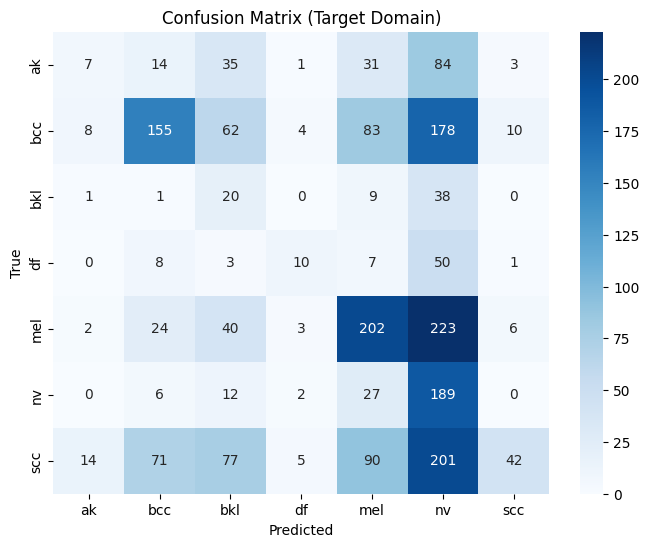

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Target Domain)")
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def unnormalize(img):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img = img.permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    return np.clip(img, 0, 1)


In [ ]:
model.eval()

samples = []  # (image, true_label, pred_label)

with torch.no_grad():
    for x, y in target_test_loader:
        x = x.to(DEVICE)
        logits, _ = model(x)
        preds = torch.argmax(logits, dim=1)

        for i in range(len(x)):
            samples.append((
                x[i].cpu(),
                y[i].item(),
                preds[i].item()
            ))


In [ ]:
def visualize_per_class(
    samples,
    class_names,
    samples_per_class=5,
    correct_only=False
):
    num_classes = len(class_names)

    plt.figure(figsize=(samples_per_class * 3, num_classes * 3))

    plot_idx = 1
    for cls in range(num_classes):
        cls_samples = [
            s for s in samples
            if s[1] == cls and
               (not correct_only or s[1] == s[2])
        ][:samples_per_class]

        for img, true, pred in cls_samples:
            plt.subplot(num_classes, samples_per_class, plot_idx)
            plt.imshow(unnormalize(img))
            plt.axis("off")

            title = f"T: {class_names[true]}\nP: {class_names[pred]}"
            color = "green" if true == pred else "red"
            plt.title(title, color=color, fontsize=9)

            plot_idx += 1

    plt.tight_layout()
    plt.show()


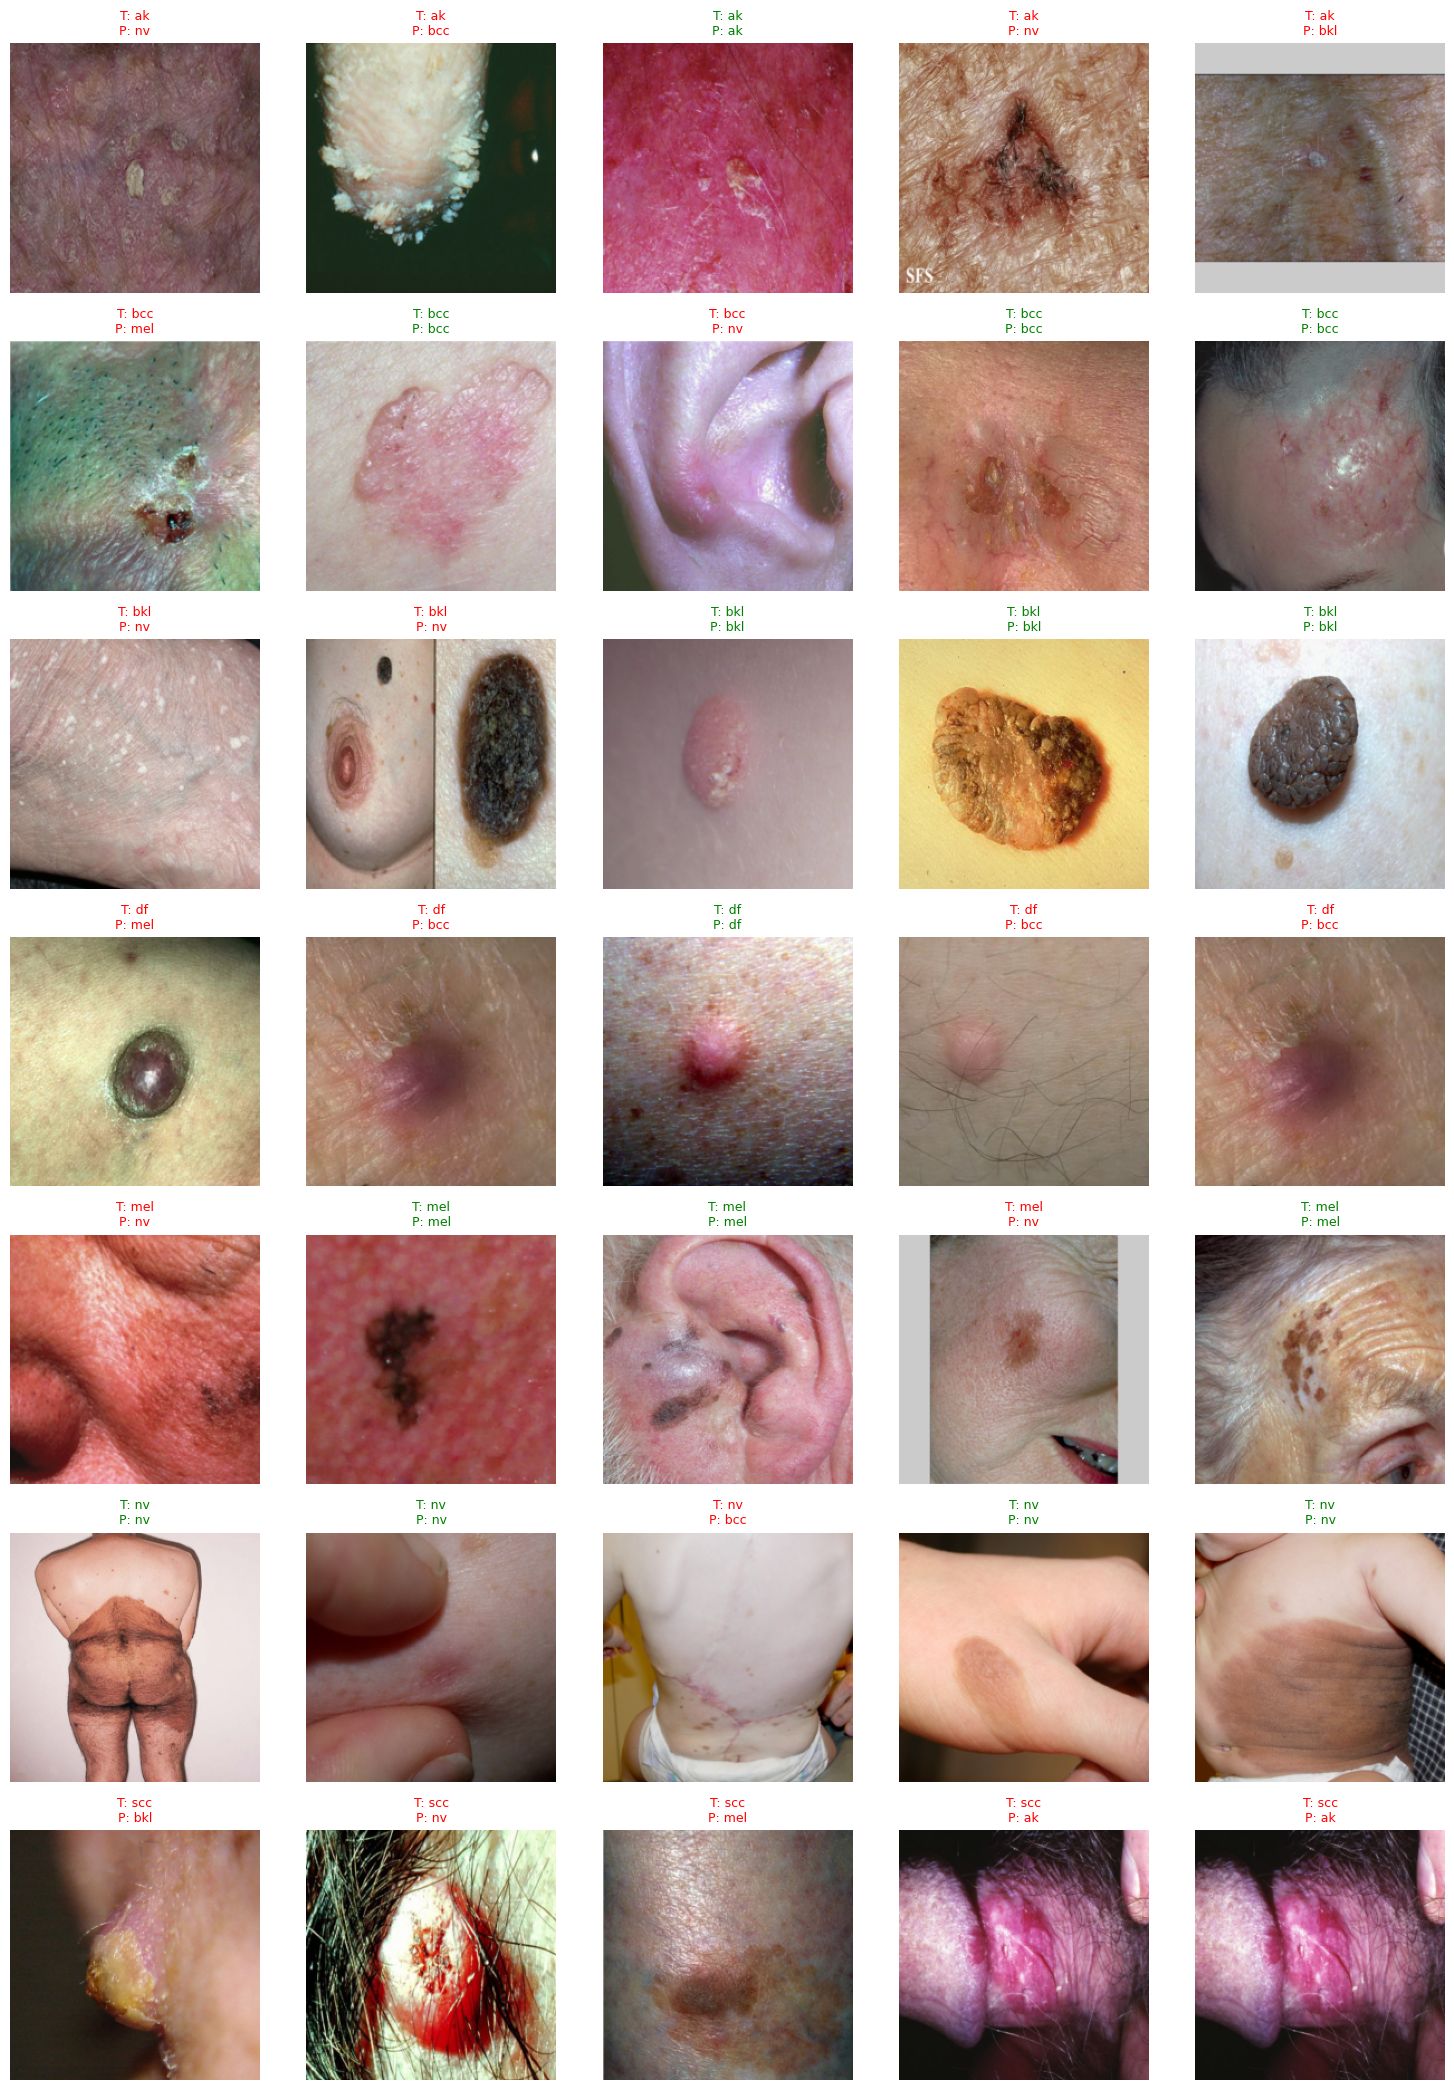

In [ ]:
visualize_per_class(
    samples,
    class_names,
    samples_per_class=5
)
